# 13. Semantic Chunking

Split where the *meaning* changes: a breakpoint appears when neighbouring sentences are dissimilar.

[![X](https://img.shields.io/badge/X-000000?style=for-the-badge&logo=x&logoColor=white)](https://x.com/techwith_ram) [![GitHub](https://img.shields.io/badge/GitHub-181717?style=for-the-badge&logo=github&logoColor=white)](https://github.com/Ramakm) [![LinkedIn](https://img.shields.io/badge/LinkedIn-0A66C2?style=for-the-badge&logo=linkedin&logoColor=white)](https://www.linkedin.com/in/ramakrushnamohapatra/) [![Instagram](https://img.shields.io/badge/Instagram-E4405F?style=for-the-badge&logo=instagram&logoColor=white)](https://instagram.com/techwith.ram) [![Medium](https://img.shields.io/badge/Medium-000000?style=for-the-badge&logo=medium&logoColor=white)](https://medium.com/@techwithram)

## Why this matters

Fixed-size chunking cuts text wherever the character counter says, even mid-idea. **Semantic chunking** looks at the meaning: embed each sentence, measure the distance between neighbours, and start a new chunk where the topic shifts (a spike in distance).

## How it works

1. Split into sentences
2. Embed every sentence
3. Compute distance between sentence i and i+1
4. Find breakpoints: distances above a percentile threshold
5. Join sentences between breakpoints into chunks

```text
 sentence distances:  .1 .1 .2 [.7] .1 .2 [.8] .1
                                ^ break        ^ break
 chunks:              [s1 s2 s3 s4] [s5 s6 s7] [s8 ...]
```

## Prerequisites

Needs a running Ollama server (`ollama serve`) with `llama3.2` pulled, plus the shared helpers in `../common.py`.

In [1]:
import sys
sys.path.insert(0, "..")
from common import *

text = load_text()
sentences = split_sentences(text.replace("## ", "").replace("# ", ""))
vecs = embed(sentences)
print(len(sentences), "sentences")

W1028 12:24:07.045000 13971 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


65 sentences


Distance between sentence *i* and *i+1* is `1 - cosine`. Spikes above a percentile threshold mark topic changes.

In [2]:
import numpy as np

dist = 1 - np.sum(vecs[:-1] * vecs[1:], axis=1)
threshold = np.percentile(dist, 85)
breaks = [i + 1 for i, d in enumerate(dist) if d > threshold]

semantic_chunks, start = [], 0
for b in breaks + [len(sentences)]:
    semantic_chunks.append(" ".join(sentences[start:b]))
    start = b
print(f"threshold={threshold:.3f}  ->  {len(semantic_chunks)} semantic chunks")
print(semantic_chunks[3][:300])

threshold=0.866  ->  11 semantic chunks
Evaluating RAG Systems

A RAG system has two parts to evaluate: retrieval and generation. Retrieval is measured with hit rate, recall at k and mean reciprocal rank, which averages 1 divided by the rank of the first correct result. Generation is measured with faithfulness, which checks that every cla


In [3]:
sem_store = build_store(semantic_chunks)
query = "What is the all-MiniLM-L6-v2 model good for?"
response, hits = rag(query, sem_store, k=2)
show(hits); print(response)

0.236  A basic RAG pipeline has four stages: ingest documents, split them into chunks, index the chunks as embeddings, and at query time retrieve the closest chunks an...
0.186  Security and Privacy  Retrieved text is untrusted input. A malicious document can contain instructions that try to hijack the model, which is called indirect pr...
According to context [1], the all-MiniLM-L6-v2 model is popular for local experiments because it is small and fast.


## Visualise the breakpoints
Spikes above the threshold line are where chunks are cut.

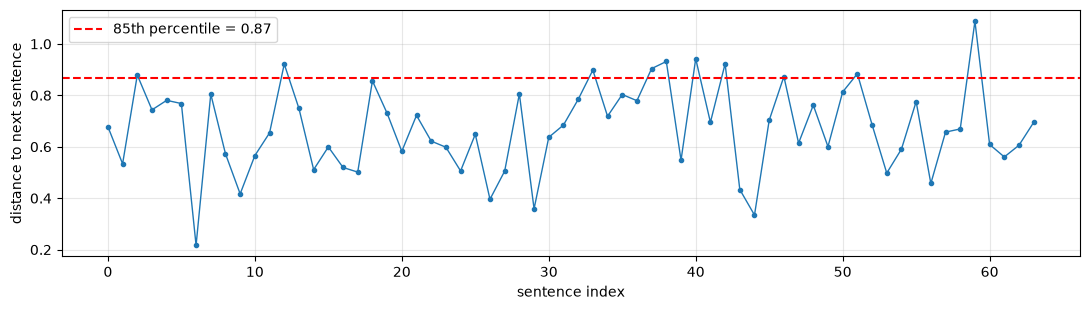

In [4]:
import matplotlib.pyplot as plt
plt.figure(figsize=(11, 3.2))
plt.plot(dist, marker=".", lw=1)
plt.axhline(threshold, color="red", ls="--", label=f"85th percentile = {threshold:.2f}")
plt.xlabel("sentence index"); plt.ylabel("distance to next sentence"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## Sensitivity to the percentile
Higher percentile = fewer, larger chunks.

In [5]:
import pandas as pd
rows = []
for pct in [70, 80, 85, 90, 95]:
    thr = np.percentile(dist, pct)
    cuts = [i + 1 for i, d in enumerate(dist) if d > thr]
    pieces, s0 = [], 0
    for b in cuts + [len(sentences)]:
        pieces.append(" ".join(sentences[s0:b])); s0 = b
    st = build_store(pieces)
    r = evaluate_retriever(st.search, k=3)
    rows.append({"percentile": pct, "chunks": len(pieces), "avg_chars": int(np.mean([len(p) for p in pieces])), "hit@3": r["hit_rate@3"], "MRR": r["MRR"]})
pd.DataFrame(rows).set_index("percentile")

,chunks,avg_chars,hit@3,MRR
percentile,,,,
70,20,403,0.95,0.93
80,14,577,1.00,0.94
85,11,735,0.85,0.76
90,8,1011,0.85,0.69
95,5,1618,0.85,0.80


## Compare against fixed-size chunking

In [6]:
fixed = build_store(chunk_text(text, size=int(np.mean([len(c) for c in semantic_chunks])), overlap=50))
compare_retrievers({"fixed-size (same avg size)": fixed.search, "semantic (85th pct)": sem_store.search}, k=3)

,hit@1,hit@3,MRR
method,,,
fixed-size (same avg size),0.8,0.95,0.88
semantic (85th pct),0.7,0.85,0.76


## Trade-offs

| Strengths | Weaknesses |
|---|---|
| Chunks respect topic boundaries | Needs an embedding pass over every sentence |
| No arbitrary mid-sentence cuts | Chunk sizes are uneven (can be huge) |
| Adapts to document structure | Threshold needs tuning; short sentences are noisy |

## When to use it

Long, flowing documents with weak or no headings. If you have reliable headings, split on those first.

## Experiments to try

- Cap the maximum chunk size and re-split big chunks.
- Use a sliding window of 3 sentences to smooth the distances.
- Try a standard-deviation threshold instead of a percentile.

## Key takeaways

- Topic shifts show up as embedding distance spikes.
- Threshold choice controls chunk size.
- Compare with fixed-size at equal average size.

---
**Next:** [14. Relevant Segment Extraction (RSE)](../14_relevant_segment_extraction/relevant_segment_extraction.ipynb)